<table align="left" style="border-style: hidden" class="table"> <tr><td class="col-md-2"><img style="float: left; width: 200px; height: 200px;" src="../logo.png" alt="Data 140 Logo" style="width: 120px;"/></td><td><div align="left"><h3 style="margin-top: 0;">Probability for Data Science</h3><h4 style="margin-top: 20px;">UC Berkeley, Spring 2026</h4><p>Ani Adhikari</p>CC BY-NC-SA 4.0</div></td></tr></table><!-- not in pdf -->

This content is protected and may not be shared, uploaded, or distributed.

# Homework 12 (Due Monday, April 27th at 5 PM)

In [13]:
import warnings
warnings.filterwarnings('ignore')

from prob140 import *
from datascience import *
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
matplotlib.style.use('fivethirtyeight')

In [14]:
from hw12_grader import Autograder
grader = Autograder()

### Instructions

#### **Questions 1, 2, and 3 can be answered based on Tuesday's lecture (and past content) alone.** ####

#### **We strongly encourage you to attempt Questions 1 and 2 independently, relying on the provided textbook sections, your own reasoning, and our AI tools (see below). If you find yourself stuck, we recommend attending office hours or homework party or posting your questions on Ed. If you're having trouble getting started on problems without the use of AI, we encourage you to follow our recommendation.** ####

Your homeworks will generally have two components: a written portion and a portion that also involves code.  Written work should be completed on paper, and coding questions should be done in the notebook. Start the work for the written portions of each section on a new page. You are welcome to $\LaTeX$ your answers to the written portions, but staff will not be able to assist you with $\LaTeX$ related issues. 

It is your responsibility to ensure that both components of the homework are submitted completely and properly to Gradescope. **Make sure to assign each page of your pdf to the correct question. Refer to the bottom of the notebook for submission instructions.**


### How to Do Your Homework ###
The point of homework is for you to try your hand at using what you've learned in class. The steps to follow:

- Go to lecture and sections, and also go over the relevant text sections before starting on the homework. This will remind you what was covered in class, and the text will typically contain examples not covered in lecture. The weekly Study Guide will list what you should read.
- Work on some of the practice problems before starting on the homework.
- Attempt the homework problems by yourself with the text, section work, and practice materials all at hand. Sometimes the week's lab will help as well. The two steps above will help this step go faster and be more fruitful.
- At this point, seek help if you need it. Don't ask how to do the problem — ask how to get started, or for a nudge to get you past where you are stuck. Always say what you have already tried. That helps us help you more effectively.
- For a good measure of your understanding, keep track of the fraction of the homework you can do by yourself or with minimal help. It's a better measure than your homework score, and only you can measure it.


### Rules for Homework ###
- Every answer should contain a calculation or reasoning. For example, a calculation such as $(1/3)(0.8) + (2/3)(0.7)$ or `sum([(1/3)*0.8, (2/3)*0.7])`is fine without further explanation or simplification. If we want you to simplify, we'll ask you to. But just ${5 \choose 2}$ by itself is not fine; write "we want any 2 out of the 5 frogs and they can appear in any order" or whatever reasoning you used. Reasoning can be brief and abbreviated, e.g. "product rule" or "not mutually exclusive."
- You may consult others (see "How to Do Your Homework" above) but you must write up your own answers using your own words, notation, and sequence of steps.
- We'll be using Gradescope. You must submit the homework according to the instructions at the end of homework set.

### **[MUST READ] Special Rules on this HW for Jupytutor**  ###
- In this homework, we are demoing a new AI Tutor for Data 140 called Jupytutor.
- The tutor will be available to help you solve Question 2 only. It will appear the below autograder cell if you fail the test case.
- If you do not want to use the tutor, click the 3 dots in the bottom left corner, and click "Turn off Jupytutor for this notebook".
- It should not appear below any other cells, but if it does, you should ignore the outputs of those windows as the AI is missing context for the other questions.
- **Grading for Question 2:** Although we provide an autograder for Q2 to check your work, you must still show your work and answer in the written part of the homework. **Passing the autograder alone does not guarantee full credit for Q2**.
- Recommended Usage: ask "how do I start/continue this question?" if you are stuck. The AI is familiar with parts of our course textbook and notation.
- If any technical issues with Jupytutor arise, please post on Ed.

## **We will not grade assignments which do not have pages correctly selected for each question.** ##

\newpage


## 1. Overlapping Counts ##
Consider a sequence of i.i.d. Bernoulli $(p)$ trials. Consider the three variables $X$, $Y$, and $V$ defined by:

- $X$ is the number of successes in trials 1 through 100
- $Y$ is the number of successes in trials 51 through 100
- $V$ is the number of successes in trials 51 through 150

**a)** For each of $X$, $Y$, and $V$, say what the distribution is and provide the parameters.

**b)** Fix $k$ in the range $0, 1, \ldots, 100$ and find the conditional distribution of $Y$ given $X = k$. Recognize this as a famous one and provide the parameters. Start with $P(Y = y|X=x)$ and use the [Division Rule](https://data140.org/textbook/content/chapter-02/multiplication/#division-rule).

**c)** Find the least squares predictor of $Y$ based on $X$ and say whether it is a linear function of $X$. (If it is, then the best linear predictor is in fact the best among all predictors.) Find $Var(Y \mid X)$. For a reminder of the least squares predictor, read through [Ch. 22.2.2](https://data140.org/textbook/content/chapter-22/least-squares-predictor/#best-predictor) (Least Squares Predictor).

**d)** Find $E(V \mid X)$, $Var(V \mid X)$, and the correlation $r(X, V)$. The equation for correlation can be found [here](https://data140.org/textbook/content/chapter-13/covariance/#correlation).

**e)** Simulate 20,000 $(X, V)$ pairs for $p = 0.5$ and draw the scatter plot of the observed points. Plot $E(V \mid X)$ as a function of $X$ on the same plot. Use the cell below. The arrays `x` and `v` should contain the observed values of $X$ and $V$. The array `exp_V_given_x` should contain $E(V \mid X = x)$ for each $x$ in `x`, using the formula you derived in **d**.

a)
X ~ binom(100, p)
Y ~ binom(50, p)
V ~ binom(100, p)


b)
P(Y = y \mid X = k) 
= \frac{P(Y=y, X=k)}{P(X = k)}
= \frac{ \binom_{50}^{k-y}p^{k-y} (1-p)^{50 - (k-y)} \binom_{50}^{y} p^y (1-p)^{50-y} }{ \binom_{100}^{k} p^k (1-p)^{100-k} }
= \frac{ \binom{50}^{k-y} \binom_{50}^{y} }{ \binom_{100}^{k} }b

hypergeometric(100, k, 50) 

c) 
b(X) = E(Y \mid X)

E(Y \mid X = k) 
= 50 * k / 100
= k/2

b(X) = E(Y \mid X) = X/2

yes

Var(Y \mid X) = 50 * \frac{X}{100} \frac{100-X}{100} \frac{50}{99

d)
1-50 次投掷成功次数为 A
101 - 150 成功次数为 W

E(V \mid X) 
= E(Y \mid X) + E(W \mid X)
= X/2 + 50p

Var(V \mid X) 
= Var(Y \mid X) + Var(W \mid X)
= 50 * \frac{X}{100} \frac{100-X}{100} \frac{50}{99} + 50p(1-p)

Var(Y) = 50p(1-p)

r(X, V) 
= \frac{ Cov(X, V) }{ \sigma_X \sigma_V }
= \frac{ Cov(A+Y, Y+W) }{ \sqrt{100p(1-p)} \sqrt{100p(1-p)} }
= \frac{ Var(Y) }{ 100p(1-p) }
= 1/2

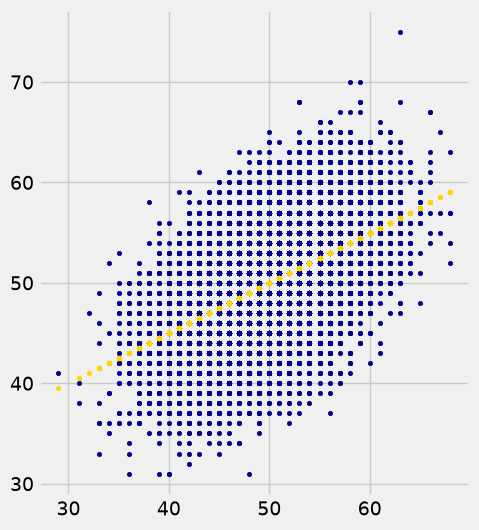

In [15]:
# Simulation for e

p = 0.5

A = stats.binom.rvs(50, p, size=20000)
Y = stats.binom.rvs(50, p, size=20000)
W = stats.binom.rvs(50, p, size=20000)

x = A + Y
v = Y + W
exp_V_given_x = x/2 + 50*p

# Don't change the lines below
plt.figure(figsize=(6, 6))
plt.axes().set_aspect('equal')
plt.xticks(np.arange(30, 71, 10))
plt.yticks(np.arange(30, 71, 10))
plt.scatter(x, v, color='darkblue', s=10)
plt.scatter(x, exp_V_given_x, color='gold', s=10);


Complete the cell below so that the `x_su` is `x` in standard units, `v_su` is `v` in standard units, and the last line evaluates to the observed correlation between `x` and `v`. Check that the output is consistent with your calculation in **d**.

In [16]:
# Part e continued

x_su = (x - np.mean(x)) / np.std(x)
v_su = (v - np.mean(v)) / np.std(v)
np.mean(x_su * v_su)

0.50789773509570402

\newpage


## 2. Midterms 1 and 2 ##

Before attempting this problem, read through [Ch. 23.2.2](https://data140.org/textbook/content/chapter-23/multivariate-normal-vectors/#sum-and-difference) (Sum and Difference of a Bivariate Normal). For a problem related to this one, look at Ch. 23.5 Ex.3, which will be done in Wednesday's section.

In a large class, the distribution of scores in Midterms 1 and 2 is approximately bivariate normal. Define the following notation.

- For $i = 1, 2$, $\mu_i$ is the class average on Midterm $i$, and $\sigma_i^2$ is the class variance on Midterm $i$
- The correlation between Midterm 1 and 2 scores in the class is $\rho$

For both questions below, **find the answer in terms of rho or constants**. Then, set the variables in the cells below to the exact answer in the case that $\rho$ = 0.6, and double check your solution with our autograder.


**a)** For approximately what proportion of the students was the Midterm 2 score (in standard units) higher than the Midterm 1 score (in standard units)? First **find the answer in terms of rho or constants**, then find the answer numerically in the cell below.

X is the standard unit scores of midterm 1
Y is the standard unit scores of midterm 2

Cov(X, Y) = r * 1 * 1

D = Y - X
E(D) = 0

Var(D) = Var(Y) + Var(X) - 2Cov(X, Y) = 1 + 1 - 2r = 2-2r

P(D > 0) = 1 - \phy( E(D) / SD(D) )

In [25]:
# answer to a
rho = 0.6 # don't change this line
sd = (2-2*rho)**0.5
q2a_answer = 1 - stats.norm.cdf(0, loc=0, scale=(2-2*rho)**0.5)
q2a_answer

0.5

In [26]:
grader.grade_q2a(q2a_answer) # don't change this line

CORRECT



**b)** For approximately what proportion of the students did the two midterm scores (each in standard units) differ by more than 1? Round your answer to the nearest 5 decimal places. First **find the answer in terms of rho or constants**, then find the answer numerically in the cell below.

P(\mid X - Y \mid > 1)
P(\mid D \mid > 1) 
P(D > 1 or D < -1) 
= 1 - P(D <= 1) + P(D < -1)
= 1 - norm(1, E(D), Var(D)) + norm(-1, E(D), Var(D)) 

In [30]:
# answer to b
rho = 0.6 # don't change this line
q2b_answer = 1 - stats.norm.cdf(1, loc=0, scale=sd) + stats.norm.cdf(-1, loc=0, scale=sd)

q2b_answer = np.round(q2b_answer, 5) # don't change this line, this rounds your answer
print(f"{q2b_answer:.5f}")

0.26355


In [31]:
grader.grade_q2b(q2b_answer) # don't change this line

CORRECT


\newpage

## 3. Normals and Coins ##

Let $X$ be standard normal. Construct a random variable $Y$ as follows:

- Toss a fair coin.
- If the coin lands heads, let $Y = X$.
- If the coin lands tails, let $Y = -X$.

**a)** Find the cdf of $Y$ and hence identify the distribution of $Y$.

**b)** Find $E(XY)$ by conditioning on the result of the toss.

**c)** Are $X$ and $Y$ uncorrelated? 

**d)** Are $X$ and $Y$ independent?

**e)** Is the joint distribution of $X$ and $Y$ bivariate normal?

a)
P(Y \le y \mid head) = P(X \le y)
P(Y \le y \mid tail) = P(-X \le y) = P(X \ge -y) = 1 - P(X < -y) 

P(Y \le y) 
= 1/2 * P(X \le y) + 1/2 * (1 - P(X < -y)) 
= (\Phi(y) - \Phi(-y) + 1) / 2
= (\Phi(y) - (1-\Phi(y)) + 1) / 2
= \Phi(y) 

normal distribution 

b)
Var(X) = E(X^2) - E(X)^2 = 1
E(X^2) = 1


E(XY \mid head) = E(X^2) = 1
E(XY \mid tail) = E(-X^2) = -1
E(XY) 
= E(XY \mid head) \times P(head) + E(XY \mid tail) \times P(tail)
= 0

c)
E(X) = 0
E(Y) = 0

E(XY) = E(X)E(Y) 

they are uncorrelated. 

d)
suppose x \in R, and x \ne 0

P(Y=x \mid X=x) = 1/2
P(Y=x) = 1/2 \times P(X=x) 

P(Y=x \mid X=x) \ne P(Y=x) 

they are not independent

e) 
they are uncorrelated, but they are not independent. so they are not bivariate normal. 

\newpage


## 4. Slices of a Normal Cake ##

This problem needs only the material of a few weeks ago, but it's here because the ideas and visualization will be helpful in the next exercise. A former 140 staff member told me how he used this method in his interview at a major quant firm and surprised the interviewer. (Yes, he got the job.) Simple, insightful solutions tend to beat tons of calculus even when the calculus is done correctly.

Let $X$ and $Y$ be independent standard normal random variables.

**a)** Find $P(X > 0, Y > 0)$. 

Yes, it's easy. But get a piece of paper and draw the event on the plane anyway. Imagine the joint density surface over the plane, and try to imagine the relevant volume under the joint density surface as a quadrant-shaped slice of a bell-shaped cake. **Then use the same approach for the next two parts.**

**b)** Find $P(X > 0, Y > X)$.

**c)** Find $P(X > 0, Y > \sqrt{3}X)$.

a) 
P(X > 0, Y > 0) = 1/4

b) 
P(X > 0, Y > X) = 1/8

c)
P(X > 0, Y > \sqrt{3}X) = 1/12

\newpage


## 5. Heights of Mothers and Daughters ##

The heights of a population of mother-daughter pairs have a bivariate normal distribution with correlation 0.5.

**a)** Of the mothers on the 90th percentile of mothers' heights, what proportion have daughters who are taller than the 90th percentile of daughters' heights?

**b)** In what proportion of mother-daughter pairs are both women taller than average? (This means the mothers are taller than the average mother and the daughters are taller than the average daughter.)

[Hint: Express standard bivariate normal variables in terms of two independent standard normal variables, and then apply the "slices of a normal cake" method.]

a) 
make X is the height of daughter, Y is the height of mother. X Y are standardized variables. 
Z and W are standard iid normal variables. 

y = norm(0, 1).ppf(0.9)
X ~ norm(\rho y, \sqrt{0.75})

x_90 = norm(0, 1).ppf(0.9)

ans = 1-norm(\rho y, \sqrt{0.75}).cdf(x_90)

b)
X ~ norm(\rho Y, \sqrt{0.75})

P(X > 0, Y > 0) 
= P(\rho Z + \sqrt{0.75} W > 0, Z > 0)
= 1/3

\newpage

## Submission Instructions ##

Many assignments throughout the course will have a written portion and a code portion. Please follow the directions below to properly submit both portions.

### Written Portion ###
*  Scan all the pages into a PDF. You can use any scanner or a phone using applications such as CamScanner. Please **DO NOT** simply take pictures using your phone. 
* Please start a new page for each question. If you have already written multiple questions on the same page, you can crop the image in CamScanner or fold your page over (the old-fashioned way). This helps expedite grading.
* It is your responsibility to check that all the work on all the scanned pages is legible.
* If you used $\LaTeX$ to do the written portions, you do not need to do any scanning; you can just download the whole notebook as a PDF via LaTeX.

### Code Portion ###
* Save your notebook using `File > Save and Checkpoint`.
* Generate a PDF file using `File > Download As > PDF via LaTeX`. This might take a few seconds and will automatically download a PDF version of this notebook.
    * If you have issues, please post a follow-up on the general Homework 12 Ed thread.
    
### Submitting ###
* Combine the PDFs from the written and code portions into one PDF. [Here](https://smallpdf.com/merge-pdf) is a useful tool for doing so. 
* Submit the assignment to Homework 12 on Gradescope. 
* **Make sure to assign each page of your pdf to the correct question.**
* **It is your responsibility to verify that all of your work shows up in your final PDF submission.**

If you are having difficulties scanning, uploading, or submitting your work, please read the [Ed Thread](https://edstem.org/us/courses/94054/discussion/7533569) on this topic and post a follow-up on the general Homework 12 Ed thread.